# Arabizi → Arabic transliteration: fixing overfitting with Sharpness-Aware Minimization (SAM)

**Paper:** Foret, Kleiner, Mobahi, Neyshabur. *Sharpness-Aware Minimization for Efficiently Improving Generalization.* arXiv:2010.01412 (Oct 2020), ICLR 2021.
Link: https://arxiv.org/abs/2010.01412 · PDF: https://arxiv.org/pdf/2010.01412 · Official code: https://github.com/google-research/sam

**Problem.** The 4-layer char-level LSTM seq2seq baseline fits the training words much better than unseen ones
(baseline: train exact-match 65.3% vs test 51.2%, CER 7.96% vs 15.04%).

**Idea.** Instead of minimising only the training loss `L(w)`, SAM minimises the *worst-case loss in a small neighbourhood* of the weights:

`min_w  max_{||ε||₂ ≤ ρ}  L(w + ε)`

It is approximated in two steps per batch:
1. Compute the gradient `g` at `w`, move to the "sharpest" nearby point `w + ε` with `ε = ρ · g / ||g||`.
2. Compute the gradient at `w + ε`, go back to `w`, and apply that gradient with the normal optimiser (Adam here).

This pushes training toward flat minima, which the paper links to better generalisation, and the paper reports robustness to label noise. That is relevant here because some Arabizi words have several valid Arabic spellings.
Cost: 2 forward/backward passes per step (about 2× training time).

**Notebook switches** (next cell): `USE_SAM=False` reruns the same pipeline as a plain Adam baseline so you can compare fairly; `RHO` is the only SAM hyper-parameter.

In [2]:
import os, copy, json, random, time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset
import matplotlib.pyplot as plt

# ----------------------------- configuration ---------------------------------
SEED          = 0
USE_SAM       = True    # False -> plain Adam (same data, same model, same early stopping)
RHO           = 0.05    # SAM neighbourhood radius; try 0.02 / 0.05 / 0.1
DROPOUT       = 0.0     # keep 0.0 to isolate the effect of SAM; baseline had none
REMAP_DIGITS  = True    # baseline mapped 8->k, 6->t, 9->s; set False to test without it
EMB, HID, LAYERS = 64, 256, 4
BATCH, LR     = 64, 1e-3
MAX_EPOCHS, PATIENCE = 30, 4
N_TRAIN       = 20000   # same split as the baseline: first 20,000 rows train, rest test
N_DEV_WORDS   = 1500    # word-disjoint dev set carved out of the training rows

DATA_PATHS = [
    "Arabizi-Arabic Parallel corpora.xlsx",
    "Arabizi-Arabic_Parallel_corpora.xlsx",
]

def set_seed(s):
    random.seed(s); np.random.seed(s)
    torch.manual_seed(s); torch.cuda.manual_seed_all(s)

set_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device, "| SAM:", USE_SAM, "| rho:", RHO)

device: cpu | SAM: True | rho: 0.05


## 1. Data
Same 20,000 / 1,499 train/test split as the baseline. Changes: exact duplicate pairs are dropped from training, and 1,500 training words are held out as a **dev set** (no word appears in both fit and dev), used for early stopping instead of peeking at test.

In [3]:
path = next((p for p in DATA_PATHS if os.path.exists(p)), None)
assert path is not None, "Dataset not found: edit DATA_PATHS"
df = pd.read_excel(path)[["Arabize", "Arabic"]].dropna().astype(str).reset_index(drop=True)

if REMAP_DIGITS:
    df["Arabize"] = (df["Arabize"].str.replace("8", "k", regex=False)
                                  .str.replace("6", "t", regex=False)
                                  .str.replace("9", "s", regex=False))

train_all = df.iloc[:N_TRAIN]
test_df   = df.iloc[N_TRAIN:]
train_df  = train_all.drop_duplicates(["Arabize", "Arabic"])

rng = np.random.RandomState(SEED)
uniq_src = train_df["Arabize"].unique()
rng.shuffle(uniq_src)
dev_src = set(uniq_src[:N_DEV_WORDS])

dev_df = train_df[train_df["Arabize"].isin(dev_src)]
fit_df = train_df[~train_df["Arabize"].isin(dev_src)]

to_pairs = lambda d: list(zip(d["Arabize"], d["Arabic"]))
fit_pairs, dev_pairs = to_pairs(fit_df), to_pairs(dev_df)
test_pairs, train_all_pairs = to_pairs(test_df), to_pairs(train_all)

seen_src = set(train_all["Arabize"])
test_unseen_pairs = [(a, b) for a, b in test_pairs if a not in seen_src]
print(f"fit {len(fit_pairs)} | dev {len(dev_pairs)} | test {len(test_pairs)} "
      f"(unseen-word test {len(test_unseen_pairs)})")
df.head()

fit 17405 | dev 1537 | test 1499 (unseen-word test 1410)


,Arabize,Arabic
0,so2al,سؤال
1,masa2,مساء
2,2sma2,أسماء
3,3marh,عمارة
4,s3adh,سعادة


In [4]:
PAD, SOS, EOS = 0, 1, 2

def make_vocab(strs):
    return {c: i + 3 for i, c in enumerate(sorted(set("".join(strs))))}

src_v = make_vocab(train_df["Arabize"])
tgt_v = make_vocab(train_df["Arabic"])
inv_tgt = {i: c for c, i in tgt_v.items()}
V = len(tgt_v) + 3
print("source chars:", len(src_v), "| target chars:", len(tgt_v))

class ArabiziDataset(Dataset):
    def __init__(self, pairs):
        self.pairs = pairs
    def __len__(self):
        return len(self.pairs)
    def __getitem__(self, i):
        s, t = self.pairs[i]
        src = [src_v[c] for c in s if c in src_v]
        tgt = [SOS] + [tgt_v[c] for c in t if c in tgt_v] + [EOS]
        return torch.tensor(src, dtype=torch.long), torch.tensor(tgt, dtype=torch.long)

def collate_fn(batch):
    srcs, tgts = zip(*batch)
    S = torch.full((len(srcs), max(len(s) for s in srcs)), PAD, dtype=torch.long)
    T = torch.full((len(tgts), max(len(t) for t in tgts)), PAD, dtype=torch.long)
    for i, (s, t) in enumerate(zip(srcs, tgts)):
        S[i, :len(s)] = s
        T[i, :len(t)] = t
    return S, T

fit_loader = DataLoader(ArabiziDataset(fit_pairs), batch_size=BATCH, shuffle=True, collate_fn=collate_fn)
dev_loader = DataLoader(ArabiziDataset(dev_pairs), batch_size=256, shuffle=False, collate_fn=collate_fn)

source chars: 71 | target chars: 39


## 2. Model (same architecture as the baseline)

In [5]:
class Seq2Seq(nn.Module):
    def __init__(self, nsrc, ntgt, emb=EMB, hid=HID, layers=LAYERS, dropout=0.0):
        super().__init__()
        d = dropout if layers > 1 else 0.0
        self.se = nn.Embedding(nsrc, emb, padding_idx=PAD)
        self.te = nn.Embedding(ntgt, emb, padding_idx=PAD)
        self.enc = nn.LSTM(emb, hid, layers, batch_first=True, dropout=d)
        self.dec = nn.LSTM(emb, hid, layers, batch_first=True, dropout=d)
        self.out = nn.Linear(hid, ntgt)

    def forward(self, x, y_in):
        _, st = self.enc(self.se(x))
        o, _ = self.dec(self.te(y_in), st)
        return self.out(o)

## 3. SAM optimiser wrapper
Written from the algorithm in Section 2 of the paper (Algorithm 1). It wraps any base optimiser (Adam here).
`perturb()` moves the weights to `w + ε`; `restore_and_step()` moves back to `w` and applies the base optimiser using the gradient computed at `w + ε`.

In [6]:
class SAM:
    """Sharpness-Aware Minimization (Foret et al., ICLR 2021, arXiv:2010.01412)."""

    def __init__(self, params, base_optimizer, rho=0.05):
        assert rho >= 0.0
        self.params = [p for p in params if p.requires_grad]
        self.base_optimizer = base_optimizer
        self.rho = rho
        self._eps = {}

    @torch.no_grad()
    def perturb(self):
        grads = [p.grad for p in self.params if p.grad is not None]
        grad_norm = torch.norm(torch.stack([g.norm(2) for g in grads]), 2)
        scale = self.rho / (grad_norm + 1e-12)
        for p in self.params:
            if p.grad is None:
                continue
            e = p.grad * scale          # epsilon = rho * g / ||g||
            p.add_(e)                   # w -> w + epsilon
            self._eps[p] = e

    @torch.no_grad()
    def restore_and_step(self):
        for p, e in self._eps.items():
            p.sub_(e)                   # back to w
        self._eps.clear()
        self.base_optimizer.step()      # update w with the gradient taken at w + epsilon

## 4. Evaluation helpers
Batched greedy decoding. Words are grouped by identical source length so no padding enters the encoder, which gives the same result as decoding one word at a time (as the baseline did) but much faster.

In [7]:
from jiwer import cer
from sacrebleu.metrics import CHRF, TER

@torch.no_grad()
def predict(words, model=None, bs=512):
    model = model or m
    model.eval()
    ids = [[src_v[c] for c in w if c in src_v] for w in words]
    preds = [""] * len(words)
    buckets = {}
    for i, s in enumerate(ids):
        if s:
            buckets.setdefault(len(s), []).append(i)

    for L, idxs in buckets.items():
        for k in range(0, len(idxs), bs):
            chunk = idxs[k:k + bs]
            X = torch.tensor([ids[i] for i in chunk], dtype=torch.long, device=device)
            _, st = model.enc(model.se(X))
            tok = torch.full((len(chunk), 1), SOS, dtype=torch.long, device=device)
            done = torch.zeros(len(chunk), dtype=torch.bool, device=device)
            outs = []
            for _ in range(2 * L + 2):
                o, st = model.dec(model.te(tok), st)
                tok = model.out(o).argmax(-1)
                outs.append(tok)
                done |= tok.squeeze(1) == EOS
                if done.all():
                    break
            rows = torch.cat(outs, 1).tolist()
            for i, row in zip(chunk, rows):
                s = []
                for t in row:
                    if t == EOS:
                        break
                    if t in inv_tgt:
                        s.append(inv_tgt[t])
                preds[i] = "".join(s)
    return preds

def evaluate(pairs, name="", verbose=True):
    srcs, refs = [a for a, _ in pairs], [b for _, b in pairs]
    preds = predict(srcs)
    em = 100 * float(np.mean([p == r for p, r in zip(preds, refs)]))
    keep = [i for i, r in enumerate(refs) if r.strip()]
    c = 100 * cer([refs[i] for i in keep], [preds[i] for i in keep])
    chrf = CHRF().corpus_score(preds, [refs]).score
    ter = TER().corpus_score(preds, [refs]).score
    res = dict(exact_match=em, cer=c, chrf=chrf, ter=ter, n=len(pairs))
    if verbose:
        print(f"{name:<22} n={len(pairs):>6} | EM {em:6.2f}% | CER {c:6.2f}% | chrF {chrf:6.2f} | TER {ter:6.2f}%")
    return res

## 5. Training
* Loss reported in the curves is always the plain cross-entropy at the **unperturbed** weights, so SAM and non-SAM runs are directly comparable.
* Early stopping on dev loss (patience `PATIENCE`), best checkpoint restored at the end.

In [8]:
set_seed(SEED)
m = Seq2Seq(len(src_v) + 3, V, dropout=DROPOUT).to(device)
base_opt = torch.optim.Adam(m.parameters(), lr=LR)
sam = SAM(m.parameters(), base_opt, rho=RHO) if USE_SAM else None
loss_fn = nn.CrossEntropyLoss(ignore_index=PAD)

history, best_dev, best_state, bad = [], float("inf"), None, 0

for ep in range(1, MAX_EPOCHS + 1):
    t0 = time.time()
    m.train()
    run = 0.0
    for X, Y in fit_loader:
        X, Y = X.to(device), Y.to(device)
        y_in, y_out = Y[:, :-1], Y[:, 1:].reshape(-1)

        # pass 1: gradient at the current weights w
        base_opt.zero_grad(set_to_none=True)
        loss = loss_fn(m(X, y_in).reshape(-1, V), y_out)
        loss.backward()

        if USE_SAM:
            sam.perturb()                                        # w -> w + epsilon
            base_opt.zero_grad(set_to_none=True)
            loss_fn(m(X, y_in).reshape(-1, V), y_out).backward() # pass 2: gradient at w + epsilon
            nn.utils.clip_grad_norm_(m.parameters(), 1.0)
            sam.restore_and_step()                               # back to w, then Adam step
        else:
            nn.utils.clip_grad_norm_(m.parameters(), 1.0)
            base_opt.step()

        run += loss.item()

    m.eval()
    dev_loss = 0.0
    with torch.no_grad():
        for X, Y in dev_loader:
            X, Y = X.to(device), Y.to(device)
            dev_loss += loss_fn(m(X, Y[:, :-1]).reshape(-1, V), Y[:, 1:].reshape(-1)).item()
    tr_loss, dev_loss = run / len(fit_loader), dev_loss / len(dev_loader)
    dev_em = evaluate(dev_pairs, verbose=False)["exact_match"]
    history.append((tr_loss, dev_loss, dev_em))
    print(f"ep {ep:02d} | train NLL {tr_loss:.4f} | dev NLL {dev_loss:.4f} | gap {dev_loss - tr_loss:+.4f}  "
          f"| dev EM {dev_em:5.2f}% | {time.time() - t0:.0f}s")

    if dev_loss < best_dev - 1e-3:
        best_dev, bad, best_state = dev_loss, 0, copy.deepcopy(m.state_dict())
    else:
        bad += 1
        if bad >= PATIENCE:
            print(f"early stop at epoch {ep} (best dev NLL {best_dev:.4f})")
            break

m.load_state_dict(best_state)

ep 01 | train NLL 2.6161 | dev NLL 2.2678 | gap -0.3483  | dev EM  0.07% | 38s
ep 02 | train NLL 1.8040 | dev NLL 1.4852 | gap -0.3187  | dev EM  1.43% | 37s
ep 03 | train NLL 1.2001 | dev NLL 0.9768 | gap -0.2233  | dev EM  9.89% | 36s
ep 04 | train NLL 0.7166 | dev NLL 0.6764 | gap -0.0403  | dev EM 25.05% | 38s
ep 05 | train NLL 0.4823 | dev NLL 0.5012 | gap +0.0189  | dev EM 35.39% | 39s
ep 06 | train NLL 0.3619 | dev NLL 0.4940 | gap +0.1321  | dev EM 40.34% | 43s
ep 07 | train NLL 0.2972 | dev NLL 0.4594 | gap +0.1622  | dev EM 44.44% | 43s
ep 08 | train NLL 0.2466 | dev NLL 0.4667 | gap +0.2202  | dev EM 48.73% | 42s
ep 09 | train NLL 0.2128 | dev NLL 0.4717 | gap +0.2589  | dev EM 48.47% | 41s
ep 10 | train NLL 0.1801 | dev NLL 0.4725 | gap +0.2924  | dev EM 50.88% | 43s
ep 11 | train NLL 0.1556 | dev NLL 0.5779 | gap +0.4222  | dev EM 51.07% | 43s
early stop at epoch 11 (best dev NLL 0.4594)


<All keys matched successfully>

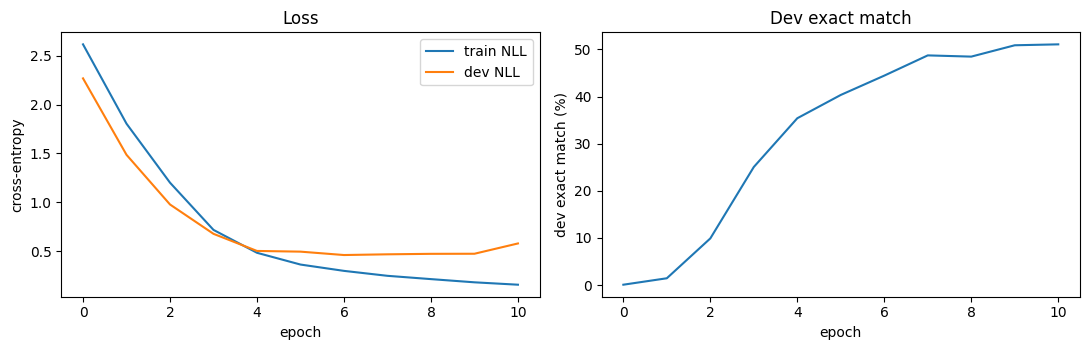

In [9]:
h = np.array(history)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(h[:, 0], label="train NLL"); ax[0].plot(h[:, 1], label="dev NLL")
ax[0].set_xlabel("epoch"); ax[0].set_ylabel("cross-entropy"); ax[0].legend(); ax[0].set_title("Loss")
ax[1].plot(h[:, 2]); ax[1].set_xlabel("epoch"); ax[1].set_ylabel("dev exact match (%)"); ax[1].set_title("Dev exact match")
plt.tight_layout(); plt.show()

## 6. Final evaluation
Compare against the baseline (no regularisation, 10 epochs): **test EM 51.17%, CER 15.04%, chrF 65.93; train EM 65.31%, CER 7.96%, chrF 82.46**.

In [10]:
tag = f"sam_rho{RHO}" if USE_SAM else "adam"
results = {
    "train": evaluate(train_all_pairs, "train (20k rows)"),
    "dev":   evaluate(dev_pairs, "dev"),
    "test":  evaluate(test_pairs, "test (all)"),
    "test_unseen": evaluate(test_unseen_pairs, "test (unseen words)"),
}
gap_em  = results["train"]["exact_match"] - results["test"]["exact_match"]
gap_cer = results["test"]["cer"] - results["train"]["cer"]
print(f"\ngeneralisation gap: EM {gap_em:.2f} pts | CER {gap_cer:.2f} pts")

with open(f"results_{tag}.json", "w") as f:
    json.dump(dict(config=dict(USE_SAM=USE_SAM, RHO=RHO, DROPOUT=DROPOUT, REMAP_DIGITS=REMAP_DIGITS,
                               epochs_run=len(history), best_dev_nll=best_dev),
                   results=results), f, indent=2)
torch.save(dict(model=m.state_dict(), src_v=src_v, tgt_v=tgt_v), f"model_{tag}.pt")
print("saved:", f"results_{tag}.json", f"model_{tag}.pt")

train (20k rows)       n= 20000 | EM  54.62% | CER  12.15% | chrF  73.00 | TER  40.47%
dev                    n=  1537 | EM  44.44% | CER  16.82% | chrF  62.29 | TER  51.65%
test (all)             n=  1499 | EM  45.23% | CER  17.26% | chrF  61.08 | TER  54.04%
test (unseen words)    n=  1410 | EM  43.90% | CER  17.66% | chrF  60.15 | TER  55.67%

generalisation gap: EM 9.39 pts | CER 5.11 pts
saved: results_sam_rho0.05.json model_sam_rho0.05.pt


In [11]:
errs = [(a, b, p) for (a, b), p in zip(test_pairs, predict([a for a, _ in test_pairs])) if p != b]
print(f"{'Arabizi':<18}{'Target':<16}{'Prediction':<16}")
for a, b, p in errs[:25]:
    print(f"{a:<18}{b:<16}{p:<16}")

Arabizi           Target          Prediction      
flstenyeh         فلسطينيه        فلستينيه        
$ele              شيلي            شيلك            
yjakr             يجاكر           يجكر            
bjamtk            بجامتك          بجمتك           
nosi              نصي             نوسي            
elthani           الثاني          الثني           
sborah            صبوره           صبره            
bnd7k              بنضحك          بندك            
bsholh            بسهوله          بشوله           
trek              طريق            تريق            
flstenyeh         فلسطينيه        فلستينيه        
tjr7              تجرح            تجره            
totlb             تطلب            توبلت           
bksrsh            بقصروش          بكسرش           
sbora             سبوره           صبره            
yns7ha            ينصحها          ينسحها          
fdy7e             فضيحه           فديني           
lelnhar           للنهار          للنانه          
a3sabha           اعصابها      

## 7. Inference

In [12]:
def translate_sentence(sentence):
    words = sentence.split(" ")
    outs = predict(words)
    return " ".join(o if o else w for o, w in zip(outs, words))

print(translate_sentence("salam 3amel eh"))

سالم عامل يه
